# VetFlow — Análise exploratória (EDA)
**Objetivo:** entender os dados antes de modelar, no roteiro *catalogar → limpar → visualizar → concluir*.

> ⚠️ **Os dados são sintéticos**, gerados de propósito com sujeira (nulos, idades impossíveis, dias negativos) para imitar a tabela consolidada por pet que a API Java monta a partir do Oracle. Nenhuma conclusão aqui vale como evidência clínica real.

In [1]:
# Funciona local (rodando da raiz do repositório) e no Google Colab.
import os, sys, subprocess
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.exists("vetflow_ai"):
    # Colab: ajuste REPO_URL para o repositório do serviço de IA
    REPO_URL = "https://github.com/Challange-Vetflow/vetflow-ai"
    subprocess.run(["git", "clone", REPO_URL, "vetflow-ai"], check=True)
    os.chdir("vetflow-ai")
sys.path.insert(0, os.getcwd())
if not os.path.exists("data/pets_features.csv"):
    subprocess.run([sys.executable, "-m", "vetflow_ai.data"], check=True)

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from vetflow_ai import config
from vetflow_ai.prep import preparar, marcar_fora_da_faixa
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
raw = pd.read_csv(config.DATA_PATH)
print(raw.shape)

(1500, 17)


## 1. Catalogar — o que temos?

In [2]:
raw.head()

,pet_id,especie,porte,idade_meses,dias_desde_ultima_vacina,intervalo_vacina_esperado_dias,vacinas_em_atraso,dias_desde_ultima_consulta,consultas_12m,faltas_consultas,tratamento_ativo,adesao_tratamento,doses_perdidas,alertas_comportamento,taxa_lembretes_ignorados,dias_desde_ultimo_login_app,risco_abandono_30d
0,1,gato,medio,111,260,384,0,206.0,3,0,1,0.86,1,0,0.250,11.0,0
1,2,cachorro,grande,137,191,345,0,108.0,7,0,0,NaN,0,1,0.375,15.0,0
2,3,gato,pequeno,31,269,357,0,65.0,3,1,0,NaN,0,0,0.000,14.0,0
3,4,gato,medio,126,389,364,0,186.0,2,1,0,NaN,0,0,0.000,7.0,0
4,5,cachorro,grande,45,221,342,0,395.0,2,0,1,0.74,1,0,0.750,10.0,1


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   pet_id                          1500 non-null   int64  
 1   especie                         1500 non-null   str    
 2   porte                           1500 non-null   str    
 3   idade_meses                     1500 non-null   int64  
 4   dias_desde_ultima_vacina        1500 non-null   int64  
 5   intervalo_vacina_esperado_dias  1500 non-null   int64  
 6   vacinas_em_atraso               1500 non-null   int64  
 7   dias_desde_ultima_consulta      1454 non-null   float64
 8   consultas_12m                   1500 non-null   int64  
 9   faltas_consultas                1500 non-null   int64  
 10  tratamento_ativo                1500 non-null   int64  
 11  adesao_tratamento               263 non-null    float64
 12  doses_perdidas                  1500 non-null

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
pet_id,1500.0,750.500000,433.157015,1.00,375.750,750.50,1125.25,1500.0
idade_meses,1500.0,69.492000,71.799991,2.00,34.000,58.00,88.00,1820.0
dias_desde_ultima_vacina,1500.0,315.484000,174.238939,-652.00,195.750,283.00,402.25,1165.0
intervalo_vacina_esperado_dias,1500.0,349.137333,45.294027,100.00,346.000,358.00,371.00,385.0
vacinas_em_atraso,1500.0,0.414000,0.988900,0.00,0.000,0.00,0.00,7.0
dias_desde_ultima_consulta,1454.0,152.071527,122.173392,3.00,65.000,120.00,201.00,753.0
consultas_12m,1500.0,2.902000,1.788443,0.00,2.000,3.00,4.00,10.0
faltas_consultas,1500.0,0.740667,0.901455,0.00,0.000,1.00,1.00,5.0
tratamento_ativo,1500.0,0.175333,0.380379,0.00,0.000,0.00,0.00,1.0
adesao_tratamento,263.0,0.799772,0.159445,0.19,0.705,0.82,0.92,1.0


### Nulos por coluna

In [5]:
nulos = raw.isna().mean().mul(100).round(1).sort_values(ascending=False)
nulos[nulos > 0].to_frame("% nulos")

,% nulos
adesao_tratamento,82.5
dias_desde_ultima_consulta,3.1
taxa_lembretes_ignorados,1.5
dias_desde_ultimo_login_app,1.5


### Valores impossíveis (fora das faixas plausíveis de `config.VALID_RANGES`)

In [6]:
_, fora = marcar_fora_da_faixa(raw)
pd.Series(fora, name="valores fora da faixa").to_frame() if fora else "nenhum"


,valores fora da faixa
idade_meses,6
dias_desde_ultima_vacina,6


**Leitura:** `adesao_tratamento` aparece com ~82% de nulos, mas isso é esperado (pet sem tratamento ativo não tem adesão a medir); nas demais colunas os nulos são poucos (< 5%). Há também em poucas colunas valores impossíveis (idade e dias desde a última vacina). Regra adotada: valor impossível vira **nulo** (não é "consertado" por palpite) e depois imputado pela **mediana**, robusta a outliers.

## 2. Limpar — a mesma função do treino e da API

In [7]:
limpo, relatorio = preparar(raw)
print({k: v for k, v in relatorio.items() if not isinstance(v, (pd.DataFrame, pd.Series))})
print(limpo.shape)

{'linhas_entrada': 1500, 'duplicados_removidos': 0, 'valores_fora_da_faixa': {'idade_meses': 6, 'dias_desde_ultima_vacina': 6}, 'nulos_para_imputar': {'idade_meses': 6, 'razao_atraso_vacina': 6, 'dias_desde_ultima_consulta': 46, 'taxa_lembretes_ignorados': 23, 'dias_desde_ultimo_login_app': 22}, 'linhas_saida': 1500}
(1500, 18)


## 3. Visualizar

### 3.1 Alvo: quantos pets em risco de abandono?

risco_abandono_30d
0    0.757
1    0.243
Name: proportion, dtype: float64


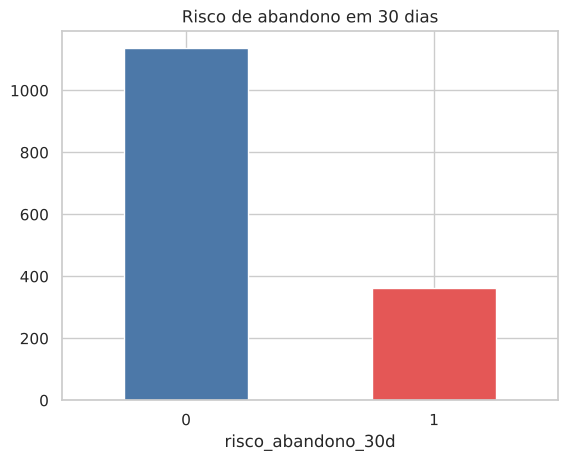

In [8]:
t = limpo[config.TARGET]
print(t.value_counts(normalize=True).round(3))
t.value_counts().plot.bar(color=["#4c78a8", "#e45756"]); plt.title("Risco de abandono em 30 dias"); plt.xticks(rotation=0); plt.show()

### 3.2 Distribuições (histogramas)

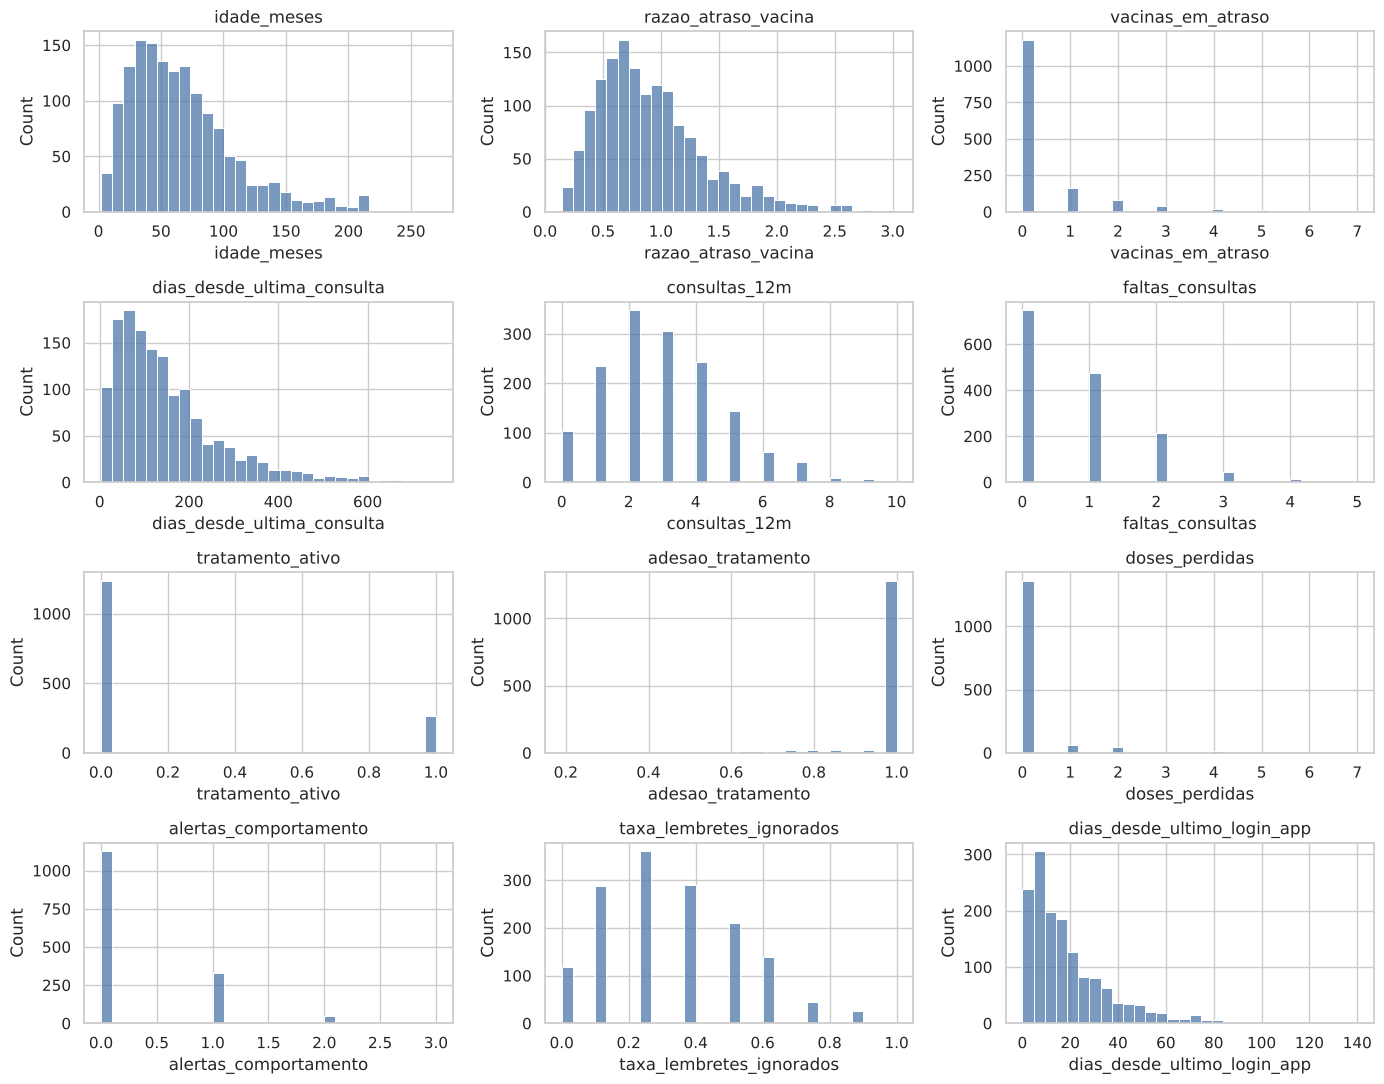

In [9]:
num = config.NUMERIC
fig, axes = plt.subplots(4, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), num):
    sns.histplot(limpo[col].dropna(), bins=30, ax=ax, color="#4c78a8"); ax.set_title(col)
plt.tight_layout(); plt.show()

### 3.3 Variáveis vs. risco (boxplots)

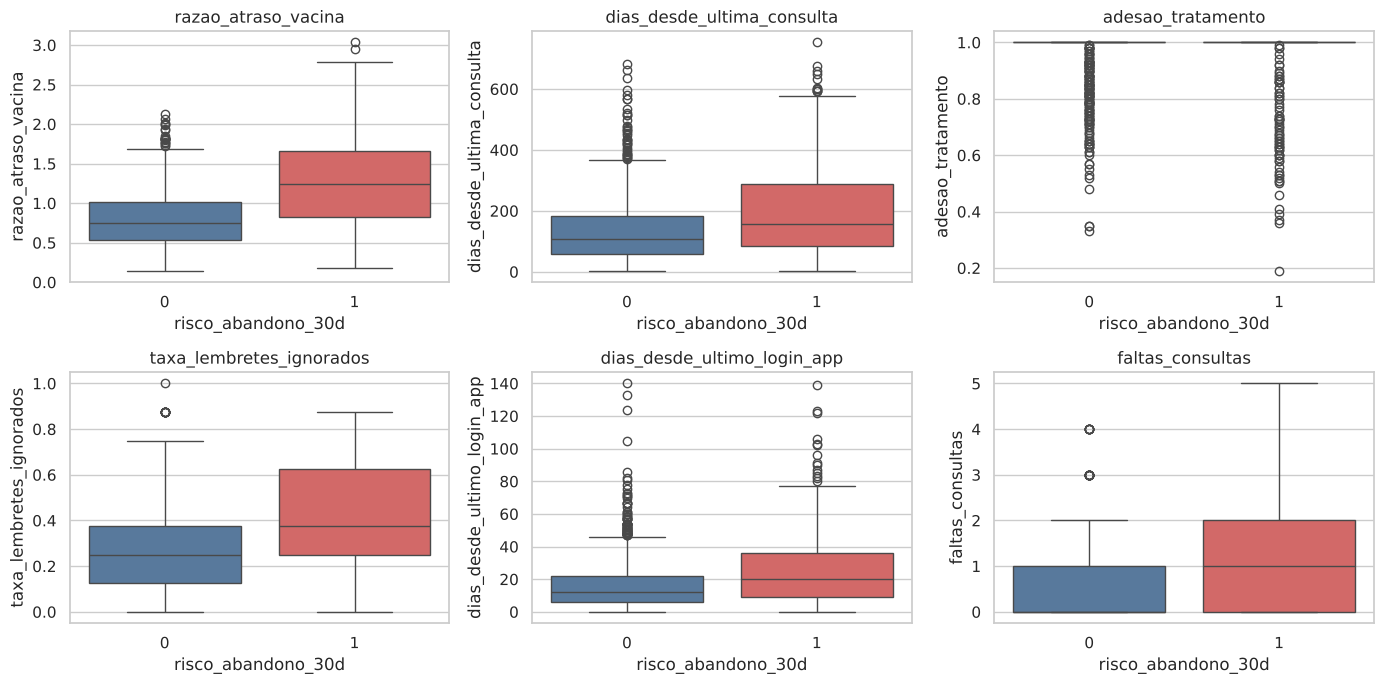

In [10]:
top = ["razao_atraso_vacina", "dias_desde_ultima_consulta", "adesao_tratamento",
       "taxa_lembretes_ignorados", "dias_desde_ultimo_login_app", "faltas_consultas"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(data=limpo, x=config.TARGET, y=col, ax=ax, palette=["#4c78a8", "#e45756"], hue=config.TARGET, legend=False)
    ax.set_title(col)
plt.tight_layout(); plt.show()

### 3.4 Espécie e porte

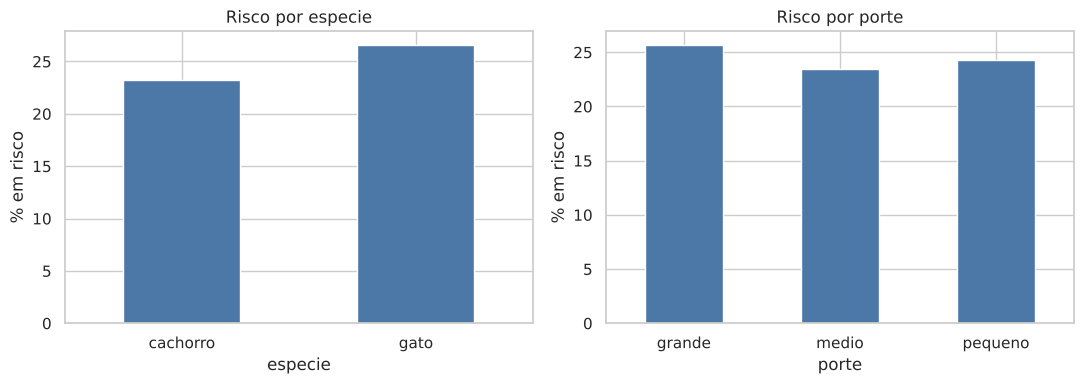

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, config.CATEGORICAL):
    limpo.groupby(col)[config.TARGET].mean().mul(100).plot.bar(ax=ax, color="#4c78a8")
    ax.set_ylabel("% em risco"); ax.set_title(f"Risco por {col}"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 3.5 Correlação

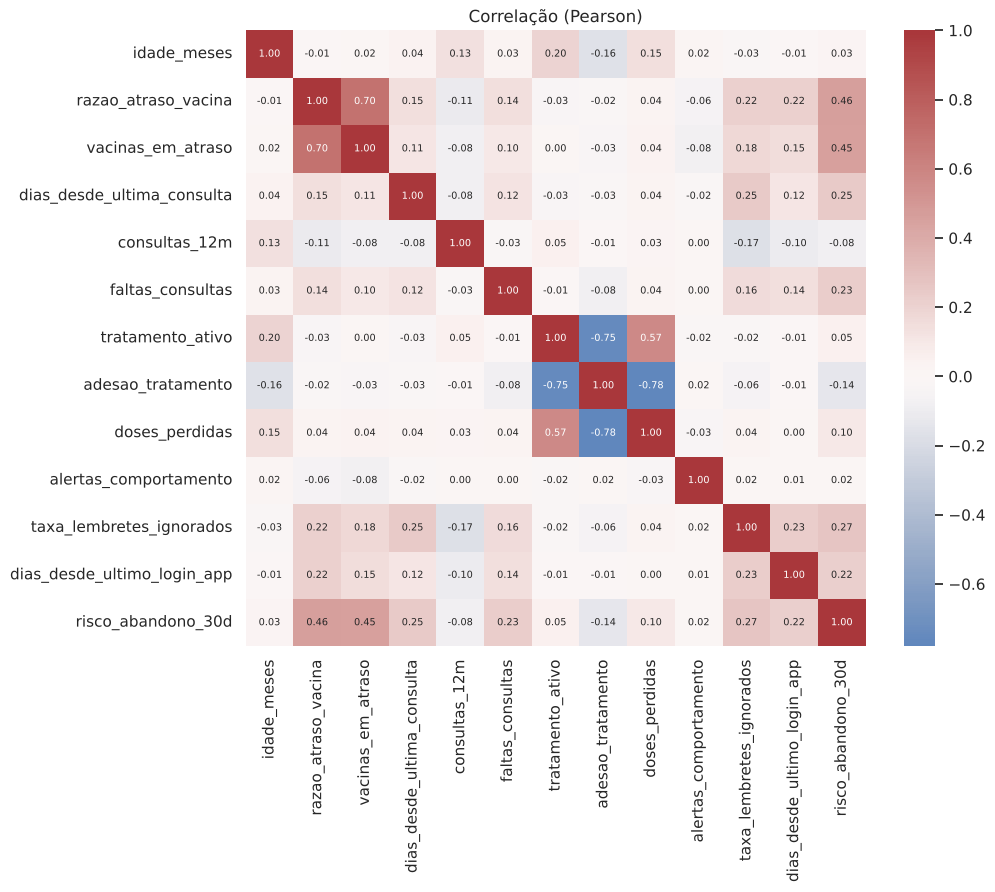

,corr com o alvo
razao_atraso_vacina,0.46
vacinas_em_atraso,0.45
taxa_lembretes_ignorados,0.27
dias_desde_ultima_consulta,0.25
faltas_consultas,0.23
dias_desde_ultimo_login_app,0.22
adesao_tratamento,-0.14
doses_perdidas,0.10
consultas_12m,-0.08
tratamento_ativo,0.05


In [12]:
corr = limpo[num + [config.TARGET]].corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlação (Pearson)"); plt.show()
corr[config.TARGET].drop(config.TARGET).sort_values(key=abs, ascending=False).round(2).to_frame("corr com o alvo")

## 4. Concluir

* **Qualidade:** os dados vêm sujos de propósito; a limpeza (fora da faixa → nulo → mediana) é a mesma função usada no treino e na API (`vetflow_ai.prep.preparar`), então o modelo nunca vê dado tratado de forma diferente em produção.
* **Sinal:** as mais associadas ao risco são **atraso de vacina relativo ao intervalo do próprio pet** (`razao_atraso_vacina`, ~0,46) e **vacinas em atraso** (~0,45), seguidas de **lembretes ignorados**, **tempo sem consulta**, **faltas** e **tempo sem abrir o app** (~0,22–0,27). A adesão ao tratamento tem correlação baixa (~-0,14) porque **82,5% dos pets não têm tratamento ativo** (adesão vazia, preenchida com 1,0 por regra de negócio). Daí a feature `razao_atraso_vacina`: personalização por atraso relativo, não absoluto.
* **Correlação ≠ causalidade:** o heatmap mostra associação, não que "ignorar lembretes causa abandono". Serve para escolher variáveis, não para provar mecanismo.
* **Limitação central:** o rótulo é sintético e gerado por um processo quase linear, o que favorece a Regressão Logística. As métricas validam a **arquitetura** (dados → modelo → API → app), não o desempenho no mundo real. O próximo passo real é treinar com os dados históricos do Oracle.
* **Próximo notebook/etapa:** comparação de modelos (`python -m vetflow_ai.train` → `reports/avaliacao_modelos.md`).